# Optical water types with TRISHNA bands

## Requirements
- A GRS L2A Sentinel-2 product (section 4); sections 1-3 need no image.

## Tutorial objectives
- Classify water reflectances into the 10 optical water types of Bi et al. (2024).
- Measure how well the TRISHNA bands separate the water types compared with Sentinel-2.
- Define a reduced OWT set adapted to TRISHNA.
- Map the OWT on a Sentinel-2 image with all bands and with TRISHNA-like bands.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 1 core, 4 GB. Run time: ~2 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
# plot style: Times-like serif fonts with LaTeX-style math (STIX, no TeX installation needed),
# larger fonts, minor ticks on all axes
plt.rcParams.update({'figure.dpi': 90, 'font.size': 14, 'font.family': 'STIXGeneral',
                     'mathtext.fontset': 'stix', 'axes.titlesize': 15, 'axes.labelsize': 15,
                     'legend.fontsize': 12, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'xtick.minor.visible': True, 'ytick.minor.visible': True})

from trishna_tbx import owt

trishna_tbx 0.0.1


## Data
> **Data paths.** On the CNES JupyterHub, point the variables below to the TREX datalake or to your project space. Outside CNES, download Sentinel-2 L1C with the *Access data - Copernicus API* tutorial. Each path can also be set through the environment variable named in the cell.

In [2]:
import os
from pathlib import Path

# ---- edit here (or set the environment variables) ------------------------------------
S2_L1C = os.environ.get('TRISHNA_TBX_S2_L1C',
    '/data/satellite/Sentinel-2/L1C/31TFJ/2025/05/26/'
    'S2B_MSIL1C_20250526T103629_N0511_R008_T31TFJ_20250526T123708.SAFE')
CAMS_FILE = os.environ.get('TRISHNA_TBX_CAMS', '/data/cams/world/cams_forecast_2025-05.nc')
# 30 km box (UTM 31N) over the Berre lagoon and the eastern Gulf of Fos
SUBSET = [(655000, 4800000, 685000, 4830000)]
L2A_DIR = os.environ.get('TRISHNA_TBX_L2A_DIR',
    '/home/harmel/Dropbox/Dropbox/work/projet/unesco/satellite/L2A')  # GRS L2A (beam profile)
L2A_TILE = 'T33PVQ'                      # Lake Chad (southern pool)
L2A_WINDOW = 'y=0:3600,x=0:960'          # 20 m pixel window with water
L2A_DATE = '2022-02-12'                  # date used by the single-image tutorials
# single-image example of the products tutorial: Loire estuary and plume, GRS v3.1.1 (Zarr pyramid,
# local S3 bucket grstbx-s3 of grstbx, read here through its folder)
L2A_EXAMPLE = os.environ.get('TRISHNA_TBX_L2A_EXAMPLE',
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2a/30TWT/2017/04/12/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
L2A_EXAMPLE_WINDOW = 'y=2700:5490,x=1500:4500'   # 20 m pixels: estuary, plume, Bourgneuf Bay
L2B_EXAMPLE = os.environ.get('TRISHNA_TBX_L2B_EXAMPLE',   # GRSl2bgen L2B of the same image
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2b/30TWT/2017/04/12/'
    'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
AERONET_HYP_DIR = os.environ.get('TRISHNA_TBX_AERONET_HYP', '/DATA/AERONET/OCv3_invRrs/data')
OUTPUT_DIR = Path(os.environ.get('TRISHNA_TBX_OUTPUT', './output')).resolve()
# ---------------------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Reference spectra
The Bi et al. (2024) mean spectra (400-900 nm) are **convolved** with each sensor's
responses: interpolating them at the band centres is not adequate for the 60-70 nm wide
TRISHNA bands. Classification uses the spectral angle (SAM), as in GRSl2bgen.

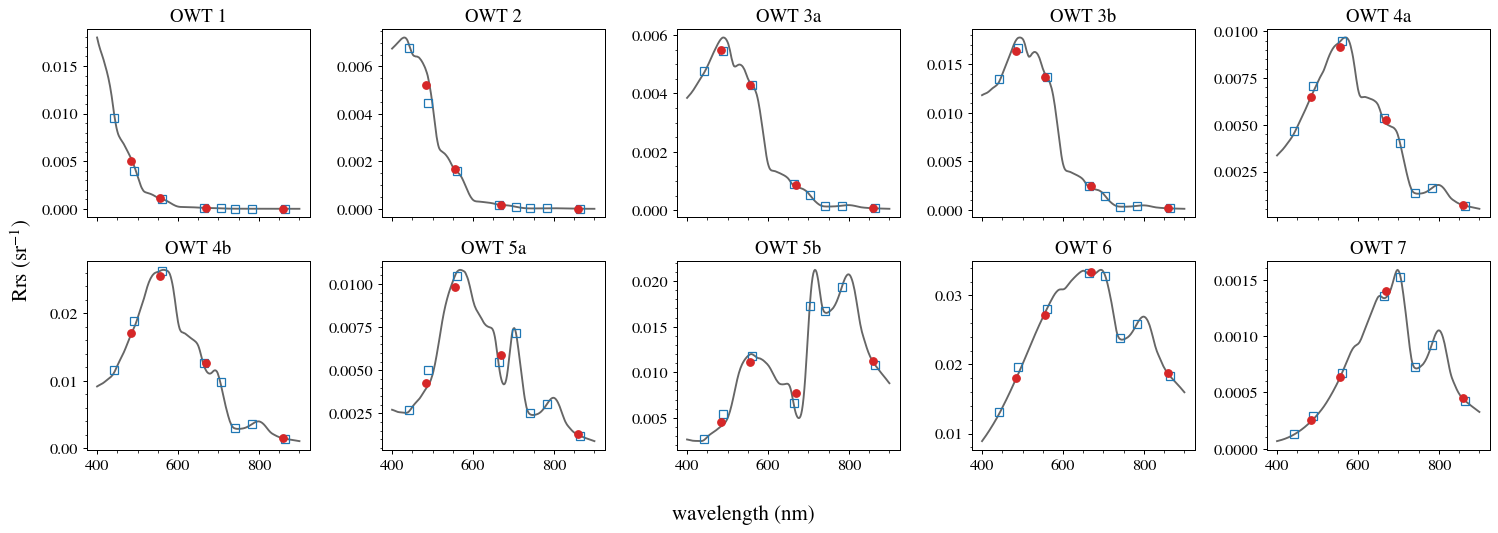

In [3]:
s2 = make_s2()
S2W = s2.subset(['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8A'], 'S2 (8 water bands)')
S2T = s2.subset(['B2', 'B3', 'B4', 'B8A'], 'S2 restricted to TRISHNA bands')
TRW = TRISHNA.subset(['Blue', 'Green', 'Red', 'NIR'], 'TRISHNA')
ref, sd = owt.load_reference('Bi2024')

fig, axs = plt.subplots(2, 5, figsize=(17, 6), sharex=True)
for ax, t in zip(axs.ravel(), ref.owt.values):
    ax.plot(ref.wl, ref.sel(owt=t), c='0.4')
    for sens, mk, c in [(S2W, 's', 'tab:blue'), (TRW, 'o', 'tab:red')]:
        cv = owt.convolve_reference(ref.sel(owt=t), sens)
        ax.plot(cv.wl, cv, mk, c=c, mfc='none' if mk == 's' else c)
    ax.set_title(f'OWT {t}')
fig.supxlabel('wavelength (nm)'); fig.supylabel('Rrs (sr$^{-1}$)'); fig.tight_layout()
fig.savefig(THUMB_DIR / 'optical_water_types_trishna.png', dpi=60)

## 2. Separability
Spectral angle (degrees) between the reference types: the smaller the angle, the harder it
is to tell the types apart.

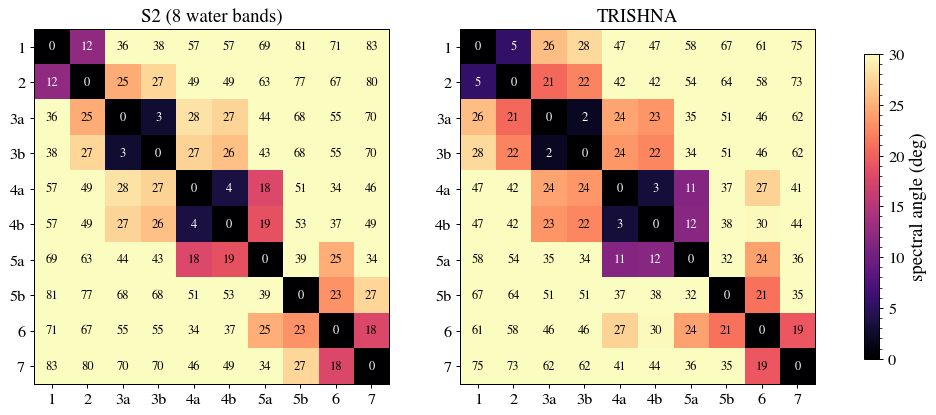

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, sens in zip(axs, [S2W, TRW]):
    sep = owt.separability(ref, sens).to_pandas()
    im = ax.imshow(sep, vmin=0, vmax=30, cmap='magma')
    ax.set_xticks(range(10), sep.columns); ax.set_yticks(range(10), sep.index); ax.minorticks_off()
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f'{sep.iloc[i, j]:.0f}', ha='center', va='center', fontsize=10,
                    color='w' if sep.iloc[i, j] < 15 else 'k')
    ax.set_title(sens.name)
fig.colorbar(im, ax=axs, shrink=.8, label='spectral angle (deg)')

## 3. Classification benchmark
Synthetic members of each type (mean + standard deviation with random amplitude and
spectral-slope perturbations) are classified with the hyperspectral spectrum (reference)
and with each band set. Noise: requirement SNR converted to Rrs (S2 averaged to 60 m).

true_owt,1,2,3a,3b,4a,4b,5a,5b,6,7,all
S2,92.0,98.0,83.0,93.0,82.0,92.0,95.0,95.0,95.0,68.0,89.0
S2-as-TRISHNA,70.0,74.0,69.0,88.0,76.0,89.0,90.0,77.0,86.0,58.0,78.0
TRISHNA,73.0,72.0,69.0,89.0,79.0,92.0,88.0,78.0,88.0,53.0,78.0
TRISHNA without NIR,76.0,73.0,69.0,83.0,65.0,85.0,57.0,69.0,80.0,55.0,71.0


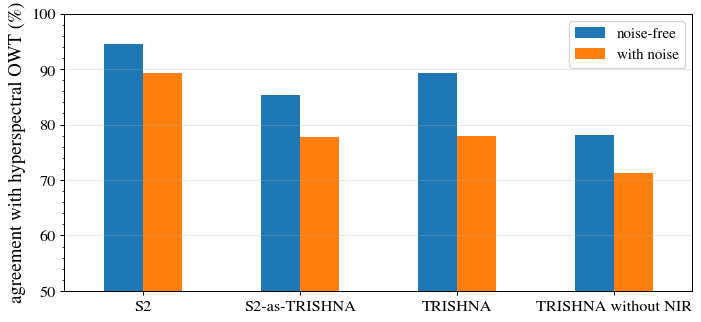

In [5]:
sensors = {'S2': S2W, 'S2-as-TRISHNA': S2T, 'TRISHNA': TRW,
           'TRISHNA without NIR': TRISHNA.subset(['Blue', 'Green', 'Red'], 'T3')}
k = 1 / (np.pi * 0.75)
noise = {n: s.noise_reflectance(30, n_aggregated=1 if n.startswith('TRISHNA') else 9)
         .assign_coords(band=s.band_names) * k for n, s in sensors.items()}
clean, conf = owt.benchmark(sensors, n=300)
noisy, conf_noisy = owt.benchmark(sensors, n=300, noise=noise)
ax = (100 * pd.concat({'noise-free': clean.loc['all'], 'with noise': noisy.loc['all']}, axis=1)).plot.bar(
    figsize=(9, 4), rot=0)
ax.set_ylabel('agreement with hyperspectral OWT (%)'); ax.set_ylim(50, 100); ax.grid(axis='y', alpha=.3)
ax.xaxis.set_minor_locator(plt.NullLocator())
(100 * noisy).round(0).T

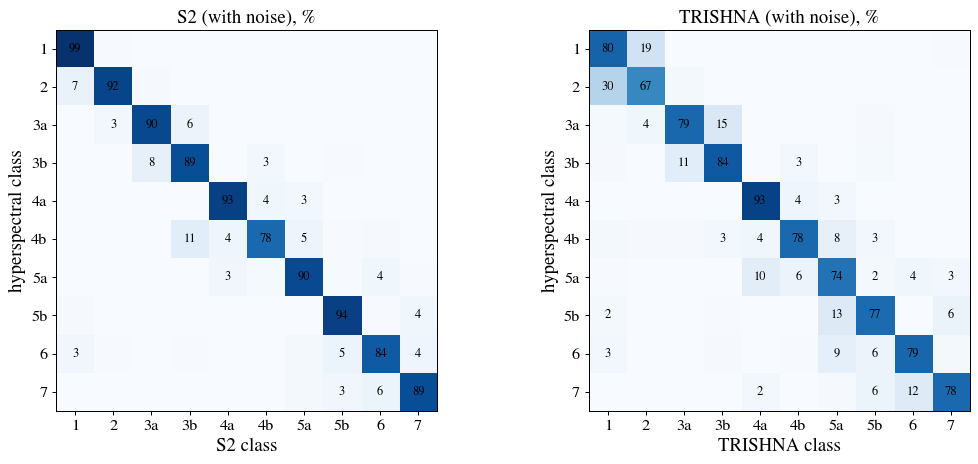

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, n in zip(axs, ['S2', 'TRISHNA']):
    c = conf_noisy[n]
    ax.imshow(100 * c.values, vmin=0, vmax=100, cmap='Blues')
    ax.set_xticks(range(c.shape[1]), c.columns); ax.set_yticks(range(c.shape[0]), c.index); ax.minorticks_off()
    for i in range(c.shape[0]):
        for j in range(c.shape[1]):
            if c.iloc[i, j] > 0.02:
                ax.text(j, i, f'{100 * c.iloc[i, j]:.0f}', ha='center', va='center', fontsize=10)
    ax.set_xlabel(f'{n} class'); ax.set_ylabel('hyperspectral class'); ax.set_title(f'{n} (with noise), %')

## 4. A TRISHNA OWT set
With TRISHNA bands, the sub-types 1/2, 3a/3b and 4a/4b differ mostly in amplitude (angle
< 6 deg). Merging them gives a 7-class set that TRISHNA can resolve much better.

In [7]:
print(owt.TRISHNA_MERGE)
members = owt.sample_members(ref, sd, n=300)
hyp, _ = owt.classify(members.sel(wl=slice(400, 900)), ref.sel(wl=slice(400, 900)), dim='wl')
rng = np.random.default_rng(1)
rows = {}
for n in ['S2', 'TRISHNA']:
    sens = sensors[n]
    x = owt.convolve_reference(members.rename(true_owt='owt'), sens).rename(owt='true_owt')
    x = x + noise[n].sel(band=x.band.values).drop_vars('wl', errors='ignore') * xr.DataArray(
        rng.standard_normal(x.shape), dims=x.dims)
    cls, _ = owt.classify(x, owt.convolve_reference(ref, sens).drop_vars('wl'), dim='band')
    rows[n] = {'10 classes': float((cls == hyp).mean()),
               '7 merged classes': float((owt.merge_classes(cls) == owt.merge_classes(hyp)).mean())}
(100 * pd.DataFrame(rows)).round(1)

{'1': '1-2', '2': '1-2', '3a': '3', '3b': '3', '4a': '4', '4b': '4', '5a': '5a', '5b': '5b', '6': '6', '7': '7'}


,S2,TRISHNA
10 classes,89.3,78.4
7 merged classes,92.2,87.4


## 5. OWT map on a Sentinel-2 image
GRS L2A over Lake Chad, averaged to 60 m. The TRISHNA-like classification uses the S2 bands
490/560/665/865 nm with the references convolved with the same S2 bands.

In [8]:
from trishna_tbx.io import list_l2a, open_grs_l2a, water_mask, to_60m
files = list_l2a(L2A_DIR, L2A_TILE)
date, f = min(files, key=lambda tf: abs(tf[0] - np.datetime64(L2A_DATE)))
ds = open_grs_l2a(f, L2A_WINDOW)
rrs = to_60m(ds.Rrs.where(water_mask(ds))).load()
rrs = rrs.where((rrs.sel(wl=[490, 560, 665]) > 0).all('wl'))
print(date, f.split('/')[-1], '| 60 m water pixels:', int(rrs.sel(wl=560).notnull().sum()))

2022-02-12T09:21:11 S2A_MSIL2Agrs_20220212T092111_N0400_R093_T33PVQ_20220212T130909.nc | 60 m water pixels: 64828


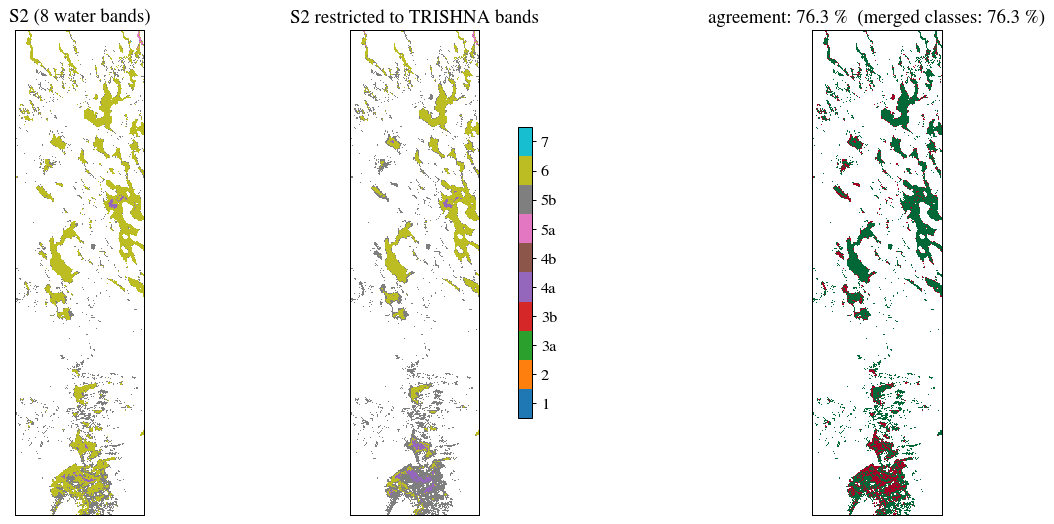

In [9]:
maps = {}
for sens in (S2W, S2T):
    r = owt.convolve_reference(ref, sens)
    x = rrs.sel(wl=r.wl.values, method='nearest').rename(wl='band').assign_coords(band=r.band.values)
    valid = x.notnull().all('band')
    cls, _ = owt.classify(x.where(valid), r.drop_vars('wl'), dim='band')
    maps[sens.name] = cls.where(valid)

labels = list(ref.owt.values)
to_idx = lambda c: xr.apply_ufunc(np.vectorize(lambda v: labels.index(v) if isinstance(v, str) else np.nan), c)
fig, axs = plt.subplots(1, 3, figsize=(17, 7), sharey=True)
cm = plt.get_cmap('tab10', 10)
for ax, (n, c) in zip(axs, maps.items()):
    im = ax.imshow(to_idx(c), cmap=cm, vmin=-.5, vmax=9.5, interpolation='nearest'); ax.set_title(n)
a, b = maps[S2W.name], maps[S2T.name]
agree = (a == b).where(a.notnull())
axs[2].imshow(agree, cmap='RdYlGn', vmin=0, vmax=1, interpolation='nearest')
axs[2].set_title(f'agreement: {100 * float(agree.mean()):.1f} %  (merged classes: '
                 f'{100 * float((owt.merge_classes(a) == owt.merge_classes(b)).where(a.notnull()).mean()):.1f} %)')
cb = fig.colorbar(im, ax=axs[:2], shrink=.6, ticks=range(10)); cb.ax.set_yticklabels(labels); cb.ax.minorticks_off()
for ax in axs: ax.set_xticks([]); ax.set_yticks([]); ax.minorticks_off()

In [10]:
ok = a.notnull().values
pd.crosstab(a.values[ok], b.values[ok], rownames=['S2 (8 bands)'], colnames=['S2-as-TRISHNA'])

S2-as-TRISHNA,4a,5a,5b,6,7
S2 (8 bands),,,,,
4a,720,9,0,108,0
5a,18,180,1,43,0
5b,0,1,20846,10,0
6,1676,50,13442,27719,1
7,0,1,0,2,1


## Take-home messages
- With the 4 TRISHNA water bands, about 9 OWT out of 10 are recovered without noise, ~8 with
  requirement noise (S2: 9.5 and 9). The 860 nm band is essential.
- The sub-types 1/2, 3a/3b and 4a/4b are hardly separable: a 7-class TRISHNA OWT set is
  more robust.
- The OWT remain a useful qualitative product (clear / productive / turbid waters) and a
  switch for algorithm selection.

## References
- Bi, S., Hieronymi, M. et al. (2024), optical water types of inland and coastal waters (10 classes), pyOWT.
- Spyrakos, E. et al. (2018), Optical types of inland and coastal waters, L&O 63.